In [2]:
# ===== CELL 1: Imports =====
import os, re, time, pickle, shutil, glob
import cv2, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("OpenCV version:", cv2.__version__)
assert hasattr(cv2, "SIFT_create"), "SIFT not found -> run: !pip install -U opencv-python"

OpenCV version: 4.14.0


In [3]:
# ===== CELL 2: Configuration =====
BASE_DIR = "landmark_project"
DB_DIR   = f"{BASE_DIR}/database"       # reference images  (one folder per landmark)
TEST_DIR = f"{BASE_DIR}/test_images"    # held-out images of the SAME landmarks (never used in the database)
UNK_DIR  = f"{BASE_DIR}/unknown_images" # landmark NOT in the database
OUT_DIR  = f"{BASE_DIR}/outputs"
for d in [DB_DIR, TEST_DIR, UNK_DIR, OUT_DIR]:
    os.makedirs(d, exist_ok=True)

# ---- dataset settings ----
N_DB, N_TEST, THUMB_W = 8, 3, 1000      # 8 reference + 3 held-out test images per landmark
MAX_DIM = 800                            # every image is resized so its longest side <= 800 px

# ---- SIFT / matching / decision parameters ----
RATIO             = 0.75   # Lowe's ratio
MIN_GOOD          = 15     # matching threshold: min reliable matches
MIN_INLIERS       = 12     # min RANSAC inliers
MIN_MATCHES_FOR_H = 8      # min matches before trying a homography
RANSAC_THRESH     = 5.0    # pixels
MARGIN            = 1.5    # best landmark must have >= 1.5x the inliers of the runner-up

LANDMARKS = {
    "Eiffel_Tower":        {"queries": ["Eiffel Tower", "Eiffel Tower Paris", "Tour Eiffel"],
                            "keys": ["eiffel"]},
    "Taj_Mahal":           {"queries": ["Taj Mahal", "Taj Mahal Agra", "Taj Mahal India"],
                            "keys": ["taj"]},
    "Great_Wall_of_China": {"queries": ["Great Wall of China", "Great Wall Badaling", "Great Wall Mutianyu"],
                            "keys": ["great wall", "great_wall", "badaling", "mutianyu"]},
    "Statue_of_Liberty":   {"queries": ["Statue of Liberty", "Statue of Liberty New York", "Statue of Liberty Liberty Island"],
                            "keys": ["liberty"]},
    "Colosseum":           {"queries": ["Colosseum Rome", "Colosseum", "Colosseo Roma"],
                            "keys": ["colosseum", "coliseum", "colosseo"]},
}
UNKNOWN = {"Pyramids_of_Giza": {"queries": ["Pyramids of Giza", "Great Pyramid of Giza", "Giza pyramid complex"],
                                "keys": ["pyramid", "giza"]}}
print("Config ready. Landmarks:", list(LANDMARKS))

Config ready. Landmarks: ['Eiffel_Tower', 'Taj_Mahal', 'Great_Wall_of_China', 'Statue_of_Liberty', 'Colosseum']


In [4]:
# ===== CELL 3: Build the dataset automatically (Wikimedia Commons) =====
HEADERS = {"User-Agent": "LandmarkSIFTLab/1.0 (university lab assignment; python-requests)"}
API = "https://commons.wikimedia.org/w/api.php"
BAD = re.compile(r"\b(map|maps|logo|flag|plan|drawing|poster|stamp|coat of arms|diagram|painting|model|"
                 r"lego|miniature|replica|postcard|sketch|engraving|illustration|vector|icon|pdf|svg)\b")

def list_images(folder):
    files = []
    for ext in ("*.jpg", "*.jpeg", "*.png"):
        files += glob.glob(os.path.join(folder, ext))
    return sorted(files)

def search_commons(query, keys, limit=50):
    params = {"action": "query", "format": "json", "generator": "search",
              "gsrsearch": f"{query} filetype:bitmap", "gsrnamespace": 6, "gsrlimit": limit,
              "prop": "imageinfo", "iiprop": "url|mime|size", "iiurlwidth": THUMB_W}
    r = requests.get(API, params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    pages = r.json().get("query", {}).get("pages", {})
    out = []
    for p in sorted(pages.values(), key=lambda x: x.get("index", 0)):
        title = p.get("title", "").lower()
        info = (p.get("imageinfo") or [{}])[0]
        if info.get("mime") != "image/jpeg":            continue
        if not any(k in title for k in keys):           continue
        if BAD.search(title):                           continue
        if info.get("width", 0) < 600:                  continue
        url = info.get("thumburl") or info.get("url")
        if url: out.append((p["title"], url))
    return out

def download(url, path, retries=4):
    for i in range(retries):
        try:
            r = requests.get(url, headers=HEADERS, timeout=60)
            if r.status_code == 200 and len(r.content) > 10000:
                img = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
                if img is not None:
                    cv2.imwrite(path, img)
                    return True
            time.sleep(5 * (i + 1) if r.status_code == 429 else 2)
        except Exception:
            time.sleep(2)
    return False

def fetch_images(name, cfg, targets):
    """targets = [(folder, how_many), ...]  filled in order."""
    need = sum(max(0, n - len(list_images(os.path.join(f, name)))) for f, n in targets)
    for f, _ in targets:
        os.makedirs(os.path.join(f, name), exist_ok=True)
    if need == 0:
        print(f"[{name}] already complete - skipped"); return
    cands, seen = [], set()
    for q in cfg["queries"]:
        try:
            for t, u in search_commons(q, cfg["keys"]):
                if t not in seen:
                    seen.add(t); cands.append((t, u))
        except Exception as e:
            print(f"  search failed for '{q}': {e}")
        if len(cands) >= need * 2: break
        time.sleep(1)
    for t, u in cands:
        slot = None
        for f, n in targets:
            folder = os.path.join(f, name)
            if len(list_images(folder)) < n:
                slot = folder; break
        if slot is None: break
        dest = os.path.join(slot, f"{name}_{len(list_images(slot)) + 1:02d}.jpg")
        download(u, dest)
        time.sleep(1)
    print(f"[{name}] " + ", ".join(f"{os.path.basename(f)}={len(list_images(os.path.join(f, name)))}" for f, _ in targets))

for name, cfg in LANDMARKS.items():
    fetch_images(name, cfg, [(DB_DIR, N_DB), (TEST_DIR, N_TEST)])
for name, cfg in UNKNOWN.items():
    fetch_images(name, cfg, [(UNK_DIR, 2)])
print("\nDataset ready.")

[Eiffel_Tower] database=8, test_images=3
[Taj_Mahal] database=8, test_images=3
[Great_Wall_of_China] database=8, test_images=3
[Statue_of_Liberty] database=8, test_images=3
[Colosseum] database=8, test_images=3
[Pyramids_of_Giza] unknown_images=2

Dataset ready.


,Landmark,Reference images,Held-out test images
0,Colosseum,8,3
1,Eiffel_Tower,8,3
2,Great_Wall_of_China,8,3
3,Statue_of_Liberty,8,3
4,Taj_Mahal,8,3


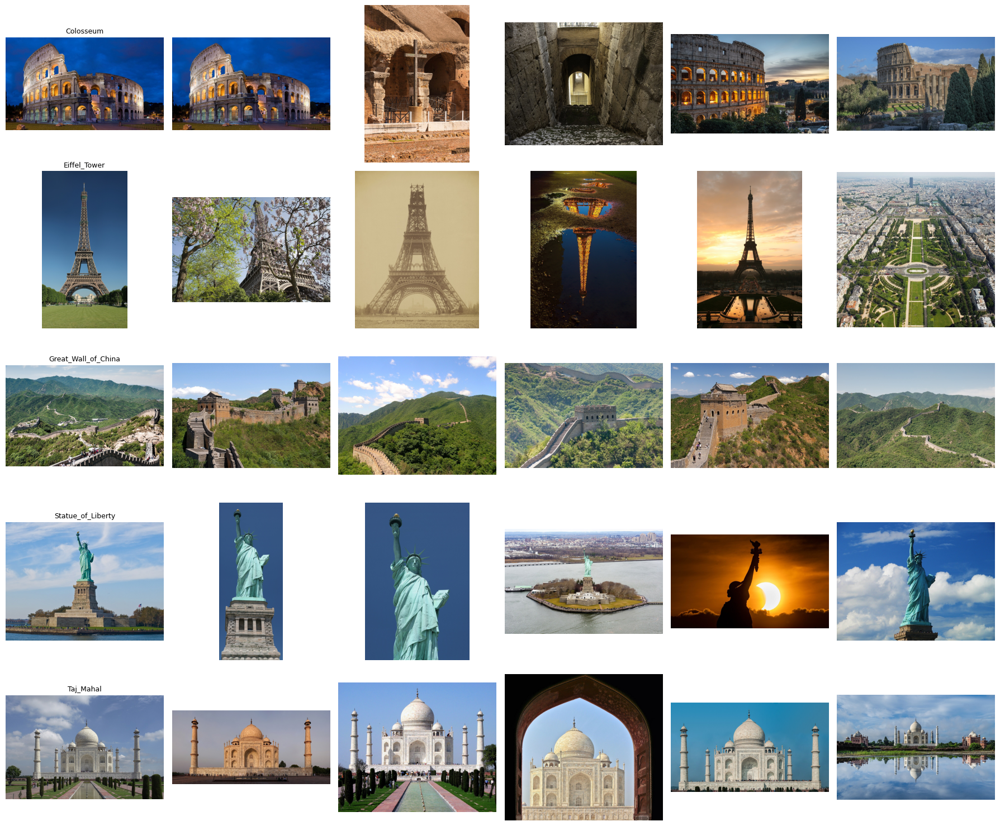

In [5]:
# ===== CELL 4: Task 1 - Show the landmark database =====
def show_bgr(ax, img, title=""):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(title, fontsize=9); ax.axis("off")

rows = []
labels = sorted(d for d in os.listdir(DB_DIR) if os.path.isdir(os.path.join(DB_DIR, d)))
for lab in labels:
    rows.append({"Landmark": lab, "Reference images": len(list_images(f"{DB_DIR}/{lab}")),
                 "Held-out test images": len(list_images(f"{TEST_DIR}/{lab}"))})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(len(labels), 6, figsize=(18, 3 * len(labels)))
axes = np.atleast_2d(axes)
for r, lab in enumerate(labels):
    files = list_images(f"{DB_DIR}/{lab}")[:6]
    for c in range(6):
        axes[r, c].axis("off")
        if c < len(files):
            img = cv2.imread(files[c])
            if img is not None:
                show_bgr(axes[r, c], img, lab if c == 0 else "")
plt.tight_layout(); plt.show()

,Images,Total_keypoints,Avg_keypoints
Landmark,,,
Colosseum,8,12003,1500.0
Eiffel_Tower,8,10838,1355.0
Great_Wall_of_China,8,12001,1500.0
Statue_of_Liberty,8,8055,1007.0
Taj_Mahal,8,11612,1452.0


Saved descriptors -> landmark_project/outputs/sift_database.pkl


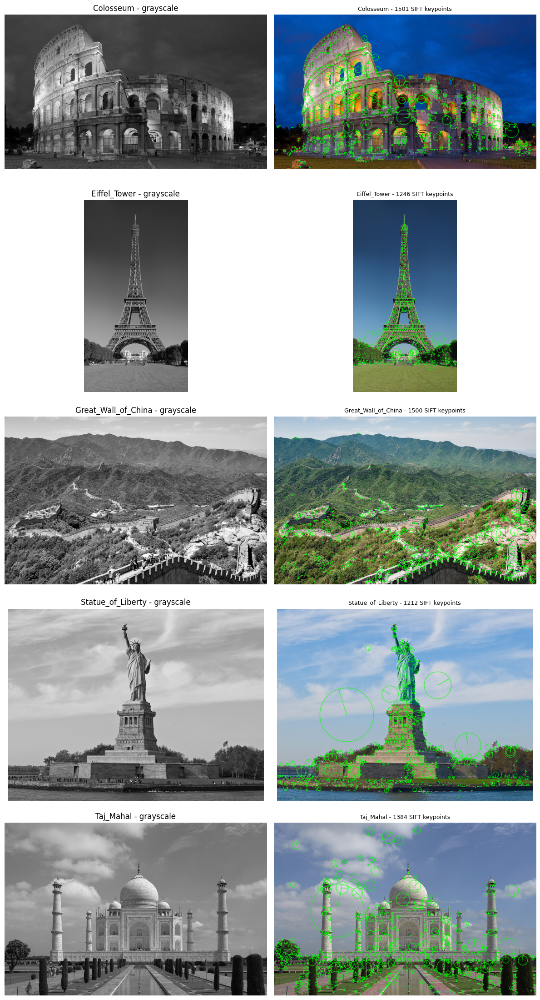

In [6]:
# ===== CELL 5: Task 2 - SIFT feature extraction on the reference images =====
sift = cv2.SIFT_create(nfeatures=1500)

def resize_max(img, max_dim=MAX_DIM):
    h, w = img.shape[:2]
    s = max_dim / max(h, w)
    if s < 1:
        img = cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    return img

def load_resized(path, max_dim=MAX_DIM):
    img = cv2.imread(path)
    if img is None:
        raise ValueError(f"Cannot read image: {path}")
    return resize_max(img, max_dim)

def extract_sift(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)              # 1. grayscale
    kp, des = sift.detectAndCompute(gray, None)                   # 2+3. keypoints + descriptors
    if des is None:
        des = np.zeros((0, 128), np.float32)
    return gray, list(kp), des

database = []                       # each entry: label, path, img, kp, des
for lab in sorted(os.listdir(DB_DIR)):
    for path in list_images(f"{DB_DIR}/{lab}"):
        try:
            img = load_resized(path)
        except Exception as e:
            print("skip:", e); continue
        gray, kp, des = extract_sift(img)
        if len(kp) < 2:
            continue
        database.append({"label": lab, "path": path, "img": img, "kp": kp, "des": des})

assert len(database) > 0, "Database is empty - check Cell 3 (dataset download)."

summary = pd.DataFrame([{"Landmark": e["label"], "Keypoints": len(e["kp"])} for e in database])
summary = summary.groupby("Landmark").agg(Images=("Keypoints", "size"),
                                          Total_keypoints=("Keypoints", "sum"),
                                          Avg_keypoints=("Keypoints", "mean")).round(0)
display(summary)

# 5. store descriptors together with landmark labels
def kp2tuple(k): return (k.pt, k.size, k.angle, k.response, k.octave, k.class_id)
store = [{"label": e["label"], "path": e["path"],
          "keypoints": [kp2tuple(k) for k in e["kp"]], "descriptors": e["des"]} for e in database]
with open(f"{OUT_DIR}/sift_database.pkl", "wb") as f:
    pickle.dump(store, f)
print("Saved descriptors ->", f"{OUT_DIR}/sift_database.pkl")

# 4. display reference images with keypoints (one per landmark)
firsts = {}
for e in database:
    firsts.setdefault(e["label"], e)
fig, axes = plt.subplots(len(firsts), 2, figsize=(12, 4.5 * len(firsts)))
axes = np.atleast_2d(axes)
for r, (lab, e) in enumerate(firsts.items()):
    gray = cv2.cvtColor(e["img"], cv2.COLOR_BGR2GRAY)
    vis = cv2.drawKeypoints(e["img"], e["kp"], None, color=(0, 255, 0),
                            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axes[r, 0].imshow(gray, cmap="gray"); axes[r, 0].set_title(f"{lab} - grayscale"); axes[r, 0].axis("off")
    show_bgr(axes[r, 1], vis, f"{lab} - {len(e['kp'])} SIFT keypoints")
plt.tight_layout(); plt.show()

Demo query: landmark_project/test_images/Colosseum/Colosseum_01.jpg


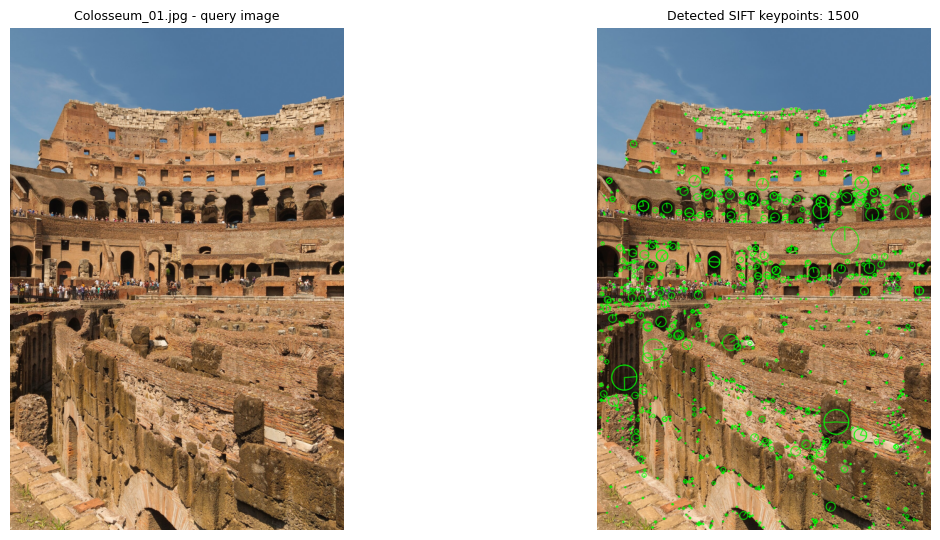

Keypoints: 1500 | Descriptor matrix shape: (1500, 128)


In [7]:
# ===== CELL 6: Task 3 - Query image processing =====
def process_query(img_bgr):
    """grayscale -> SIFT keypoints -> descriptors"""
    return extract_sift(img_bgr)

def show_query(img_bgr, title="Query"):
    gray, kp, des = process_query(img_bgr)
    vis = cv2.drawKeypoints(img_bgr, kp, None, color=(0, 255, 0),
                            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
    show_bgr(ax[0], img_bgr, f"{title} - query image")
    show_bgr(ax[1], vis, f"Detected SIFT keypoints: {len(kp)}")
    plt.tight_layout(); plt.show()
    print("Keypoints:", len(kp), "| Descriptor matrix shape:", des.shape)

# demo with the first held-out test image we can find
demo_path = None
for lab in sorted(os.listdir(TEST_DIR)):
    fs = list_images(f"{TEST_DIR}/{lab}")
    if fs: demo_path = fs[0]; break
demo_path = demo_path or database[0]["path"]
print("Demo query:", demo_path)
show_query(load_resized(demo_path), os.path.basename(demo_path))

In [8]:
# ===== CELL 7: Tasks 4 & 5 - Matching, recognition and localization =====
bf = cv2.BFMatcher(cv2.NORM_L2)                       # Brute-Force, Euclidean distance

def ratio_matches(des_q, des_r, ratio=RATIO):
    """KNN (k=2) + Lowe's ratio test. Returns list of reliable matches (queryIdx=query, trainIdx=reference)."""
    if des_q is None or des_r is None or len(des_q) < 2 or len(des_r) < 2:
        return []
    good = []
    for pair in bf.knnMatch(des_q, des_r, k=2):
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance:
            good.append(pair[0])
    return good

def verify_geometry(kp_q, kp_r, good, ref_shape, q_shape):
    """RANSAC homography + sanity checks on the projected polygon."""
    out = {"H": None, "mask": None, "inliers": 0, "polygon": None, "geom_ok": False, "msg": ""}
    if len(good) < MIN_MATCHES_FOR_H:
        out["msg"] = "Too few reliable matches for homography"; return out
    src = np.float32([kp_r[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None or mask is None:
        out["msg"] = "RANSAC failed to find a homography"; return out
    mask = mask.ravel().astype(bool)
    out["H"], out["mask"], out["inliers"] = H, mask, int(mask.sum())
    h, w = ref_shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    poly = cv2.perspectiveTransform(corners, H).reshape(-1, 2)
    out["polygon"] = poly
    if not np.all(np.isfinite(poly)):
        out["msg"] = "Invalid projection (non-finite)"; return out
    if out["inliers"] < MIN_INLIERS:
        out["msg"] = f"Too few RANSAC inliers ({out['inliers']} < {MIN_INLIERS})"; return out
    area = cv2.contourArea(poly.astype(np.float32).reshape(-1, 1, 2))
    q_area = q_shape[0] * q_shape[1]
    if not (0.005 * q_area <= area <= 6 * q_area):
        out["msg"] = "Projected region has an unrealistic size"; return out
    if not cv2.isContourConvex(poly.astype(np.float32).reshape(-1, 1, 2)):
        out["msg"] = "Projected region is not a valid convex quadrilateral"; return out
    out["geom_ok"] = True
    return out

def recognize(query_bgr):
    t0 = time.perf_counter()
    gray, kp_q, des_q = extract_sift(query_bgr)

    # best reference image per landmark (most reliable matches)
    best = {}
    for e in database:
        g = ratio_matches(des_q, e["des"])
        if e["label"] not in best or len(g) > len(best[e["label"]]["matches"]):
            best[e["label"]] = {"label": e["label"], "ref": e, "matches": g}

    cands = []
    for lab, c in best.items():
        geo = verify_geometry(kp_q, c["ref"]["kp"], c["matches"], c["ref"]["img"].shape, query_bgr.shape)
        c.update(geo); c["good"] = len(c["matches"])
        cands.append(c)
    cands.sort(key=lambda c: (c["good"], c["inliers"]), reverse=True)   # rank by reliable matches
    top = cands[0]
    others = [c["inliers"] for c in cands[1:]]
    runner_up = max(others) if others else 0

    # decision: NOT only the largest match count
    reasons = []
    if top["good"] < MIN_GOOD:
        reasons.append(f"reliable matches {top['good']} < threshold {MIN_GOOD}")
    if not top["geom_ok"]:
        reasons.append("geometric verification failed: " + (top["msg"] or "unreliable"))
    elif top["inliers"] < MARGIN * max(runner_up, 1):
        reasons.append(f"ambiguous: runner-up has {runner_up} inliers vs {top['inliers']}")
    recognized = len(reasons) == 0

    return {"query": query_bgr, "kp_q": kp_q, "n_kp": len(kp_q), "ranking": cands, "top": top,
            "recognized": recognized, "predicted": top["label"] if recognized else "Unknown",
            "reasons": reasons, "time": time.perf_counter() - t0}

def show_result(res, figsize=(20, 6)):
    q, top = res["query"], res["top"]
    fig, axes = plt.subplots(1, 3, figsize=figsize, gridspec_kw={"width_ratios": [1, 1, 2]})
    show_bgr(axes[0], q, "1) Query image")
    kp_vis = cv2.drawKeypoints(q, res["kp_q"], None, color=(0, 255, 0),
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    show_bgr(axes[1], kp_vis, f"2) SIFT keypoints ({res['n_kp']})")

    q_draw = q.copy()
    if top["geom_ok"]:
        cv2.polylines(q_draw, [np.int32(top["polygon"]).reshape(-1, 1, 2)], True, (0, 0, 255), 4, cv2.LINE_AA)
    if top["mask"] is not None and len(top["matches"]) > 0:
        matches, mask = top["matches"], top["mask"].astype(int).tolist()     # draw RANSAC inliers only
    else:
        matches, mask = top["matches"][:60], None
    # drawMatches expects (queryIdx -> img1 keypoints), so swap indices to draw reference on the left
    matches = [cv2.DMatch(m.trainIdx, m.queryIdx, m.distance) for m in matches]
    vis = cv2.drawMatches(top["ref"]["img"], top["ref"]["kp"], q_draw, res["kp_q"], matches, None,
                          matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), matchesMask=mask,
                          flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    show_bgr(axes[2], vis, f"3) Matches with {top['label']} | reliable={top['good']} | RANSAC inliers={top['inliers']}")

    status = f"RECOGNIZED: {res['predicted']}" if res["recognized"] else "REJECTED: unknown / unreliable"
    fig.suptitle(status, fontsize=16, color="green" if res["recognized"] else "red", fontweight="bold")
    plt.tight_layout(); plt.show()

    print("=" * 70)
    print("Predicted landmark   :", res["predicted"])
    print("Best candidate       :", top["label"])
    print("Reliable matches     :", top["good"])
    print("RANSAC inliers       :", top["inliers"])
    print("Processing time      : %.3f s" % res["time"])
    if res["recognized"]:
        print("Decision             : RECOGNIZED  (landmark localized with the red polygon)")
    else:
        print("Decision             : REJECTED  ->", "; ".join(res["reasons"]))
    if not top["geom_ok"]:
        print("Localization         : geometric transformation unreliable - no polygon drawn")
    print("\nCandidate ranking:")
    display(pd.DataFrame([{"Rank": i + 1, "Landmark": c["label"], "Reliable matches": c["good"],
                           "RANSAC inliers": c["inliers"],
                           "Geometry OK": c["geom_ok"]} for i, c in enumerate(res["ranking"])]))
    print("=" * 70)

print("Recognition functions ready.")

Recognition functions ready.


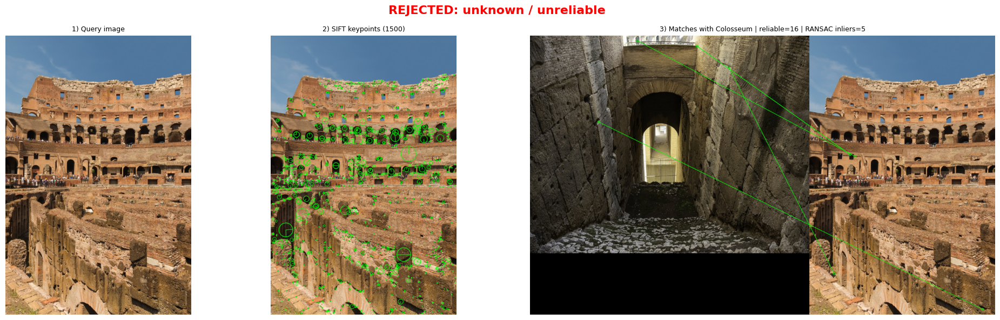

Predicted landmark   : Unknown
Best candidate       : Colosseum
Reliable matches     : 16
RANSAC inliers       : 5
Processing time      : 2.200 s
Decision             : REJECTED  -> geometric verification failed: Too few RANSAC inliers (5 < 12)
Localization         : geometric transformation unreliable - no polygon drawn

Candidate ranking:


,Rank,Landmark,Reliable matches,RANSAC inliers,Geometry OK
0,1,Colosseum,16,5,False
1,2,Eiffel_Tower,15,5,False
2,3,Statue_of_Liberty,15,4,False
3,4,Taj_Mahal,13,5,False
4,5,Great_Wall_of_China,12,5,False


In [9]:
# ===== CELL 8: Demo - recognize one query image =====
query_img = load_resized(demo_path)
result = recognize(query_img)
show_result(result)

In [10]:
# ===== CELL 9: Task 6 - Performance evaluation =====
def rotate_img(img, angle=45):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    c, s = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * s + w * c), int(h * c + w * s)
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh), borderValue=(0, 0, 0))

def resize_half(img):
    return cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

def darken(img, factor=0.4):
    return cv2.convertScaleAbs(img, alpha=factor, beta=0)

all_results, rows = [], []
def run_case(img, true_label, condition, src):
    res = recognize(img)
    correct = (res["predicted"] == true_label) if true_label != "Unknown" else (not res["recognized"])
    rows.append({"Test image": src, "Condition": condition, "True landmark": true_label,
                 "Predicted landmark": res["predicted"], "Keypoints": res["n_kp"],
                 "Reliable matches": res["top"]["good"], "RANSAC inliers": res["top"]["inliers"],
                 "Decision": "Recognized" if res["recognized"] else "Rejected",
                 "Correct": "Yes" if correct else "No", "Time (s)": round(res["time"], 3)})
    all_results.append((true_label, condition, res))

for lab in sorted(os.listdir(TEST_DIR)):
    tests = list_images(f"{TEST_DIR}/{lab}")
    if not tests: continue
    base = load_resized(tests[0]); nm = os.path.basename(tests[0])
    run_case(base,              lab, "Original",           nm)
    run_case(rotate_img(base),  lab, "Rotated 45 deg",     nm)
    run_case(resize_half(base), lab, "Resized 50%",        nm)
    run_case(darken(base),      lab, "Reduced brightness", nm)
    if len(tests) > 1:
        run_case(load_resized(tests[1]), lab, "Different viewpoint", os.path.basename(tests[1]))
for lab in sorted(os.listdir(UNK_DIR)):
    for p in list_images(f"{UNK_DIR}/{lab}")[:2]:
        run_case(load_resized(p), "Unknown", "Landmark not in database", os.path.basename(p))

df = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
display(df)
df.to_csv(f"{OUT_DIR}/experimental_results.csv", index=False)
print("Saved ->", f"{OUT_DIR}/experimental_results.csv")
print("\nOverall accuracy: %.1f%%  (%d/%d)" % (100 * (df["Correct"] == "Yes").mean(),
                                               (df["Correct"] == "Yes").sum(), len(df)))
display(df.assign(ok=(df["Correct"] == "Yes")).groupby("Condition").agg(
    Tests=("ok", "size"), Correct=("ok", "sum"), Avg_matches=("Reliable matches", "mean"),
    Avg_time_s=("Time (s)", "mean")).round(2))

,Test image,Condition,True landmark,Predicted landmark,Keypoints,Reliable matches,RANSAC inliers,Decision,Correct,Time (s)
0,Colosseum_01.jpg,Original,Colosseum,Unknown,1500,16,5,Rejected,No,2.274
1,Colosseum_01.jpg,Rotated 45 deg,Colosseum,Unknown,1500,42,6,Rejected,No,2.593
2,Colosseum_01.jpg,Resized 50%,Colosseum,Unknown,1368,12,4,Rejected,No,1.933
3,Colosseum_01.jpg,Reduced brightness,Colosseum,Unknown,1459,17,4,Rejected,No,2.154
4,Colosseum_02.jpg,Different viewpoint,Colosseum,Unknown,1500,37,7,Rejected,No,3.845
5,Eiffel_Tower_01.jpg,Original,Eiffel_Tower,Unknown,1500,15,5,Rejected,No,2.827
6,Eiffel_Tower_01.jpg,Rotated 45 deg,Eiffel_Tower,Unknown,1501,23,7,Rejected,No,2.371
7,Eiffel_Tower_01.jpg,Resized 50%,Eiffel_Tower,Unknown,769,13,5,Rejected,No,1.072
8,Eiffel_Tower_01.jpg,Reduced brightness,Eiffel_Tower,Unknown,1500,17,5,Rejected,No,2.226
9,Eiffel_Tower_02.jpg,Different viewpoint,Eiffel_Tower,Unknown,1500,17,5,Rejected,No,2.258


Saved -> landmark_project/outputs/experimental_results.csv

Overall accuracy: 37.0%  (10/27)


,Tests,Correct,Avg_matches,Avg_time_s
Condition,,,,
Different viewpoint,5,1,231.6,2.40
Landmark not in database,2,2,14.0,1.48
Original,5,2,257.2,2.31
Reduced brightness,5,2,67.6,1.46
Resized 50%,5,1,85.4,1.27
Rotated 45 deg,5,2,192.4,2.53



########  Colosseum - Original  ########


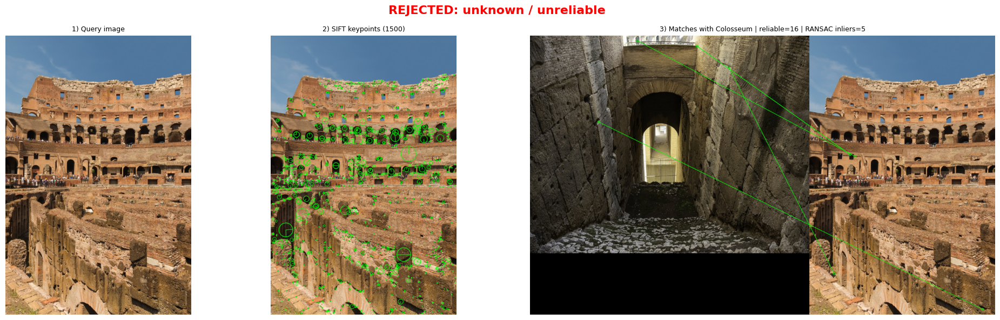

Predicted landmark   : Unknown
Best candidate       : Colosseum
Reliable matches     : 16
RANSAC inliers       : 5
Processing time      : 2.274 s
Decision             : REJECTED  -> geometric verification failed: Too few RANSAC inliers (5 < 12)
Localization         : geometric transformation unreliable - no polygon drawn

Candidate ranking:


,Rank,Landmark,Reliable matches,RANSAC inliers,Geometry OK
0,1,Colosseum,16,5,False
1,2,Eiffel_Tower,15,5,False
2,3,Statue_of_Liberty,15,4,False
3,4,Taj_Mahal,13,5,False
4,5,Great_Wall_of_China,12,5,False



########  Colosseum - Rotated 45 deg  ########


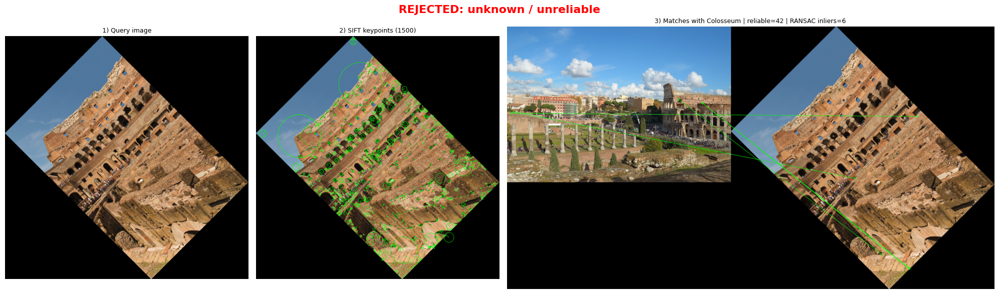

Predicted landmark   : Unknown
Best candidate       : Colosseum
Reliable matches     : 42
RANSAC inliers       : 6
Processing time      : 2.593 s
Decision             : REJECTED  -> geometric verification failed: Too few RANSAC inliers (6 < 12)
Localization         : geometric transformation unreliable - no polygon drawn

Candidate ranking:


,Rank,Landmark,Reliable matches,RANSAC inliers,Geometry OK
0,1,Colosseum,42,6,False
1,2,Taj_Mahal,33,7,False
2,3,Eiffel_Tower,24,5,False
3,4,Great_Wall_of_China,21,4,False
4,5,Statue_of_Liberty,17,5,False



########  Colosseum - Resized 50%  ########


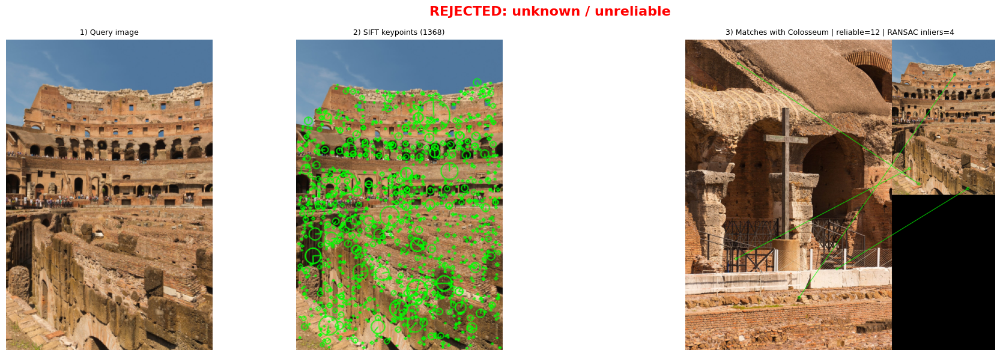

Predicted landmark   : Unknown
Best candidate       : Colosseum
Reliable matches     : 12
RANSAC inliers       : 4
Processing time      : 1.933 s
Decision             : REJECTED  -> reliable matches 12 < threshold 15; geometric verification failed: Too few RANSAC inliers (4 < 12)
Localization         : geometric transformation unreliable - no polygon drawn

Candidate ranking:


,Rank,Landmark,Reliable matches,RANSAC inliers,Geometry OK
0,1,Colosseum,12,4,False
1,2,Eiffel_Tower,10,4,False
2,3,Great_Wall_of_China,8,4,False
3,4,Statue_of_Liberty,8,4,False
4,5,Taj_Mahal,7,0,False



########  Colosseum - Reduced brightness  ########


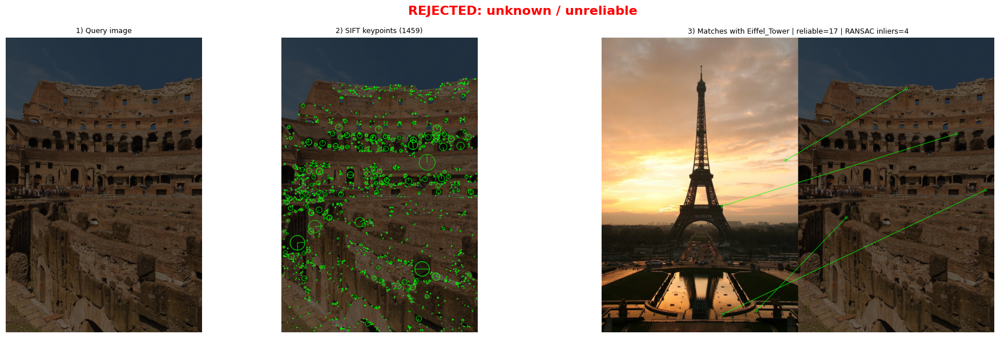

Predicted landmark   : Unknown
Best candidate       : Eiffel_Tower
Reliable matches     : 17
RANSAC inliers       : 4
Processing time      : 2.154 s
Decision             : REJECTED  -> geometric verification failed: Too few RANSAC inliers (4 < 12)
Localization         : geometric transformation unreliable - no polygon drawn

Candidate ranking:


,Rank,Landmark,Reliable matches,RANSAC inliers,Geometry OK
0,1,Eiffel_Tower,17,4,False
1,2,Statue_of_Liberty,16,5,False
2,3,Colosseum,16,4,False
3,4,Taj_Mahal,13,4,False
4,5,Great_Wall_of_China,11,4,False



########  Colosseum - Different viewpoint  ########


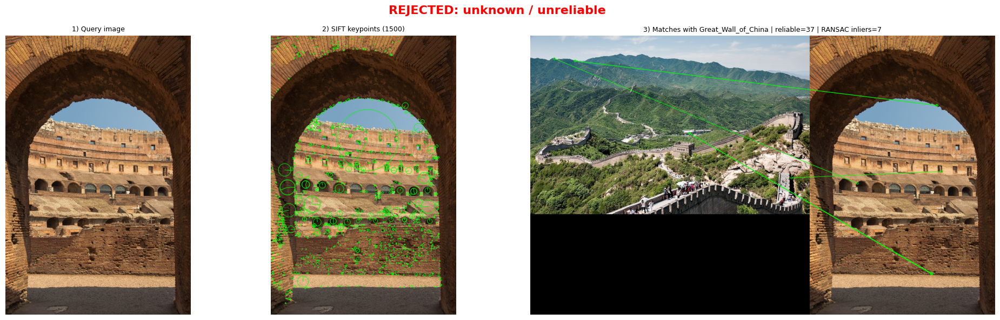

Predicted landmark   : Unknown
Best candidate       : Great_Wall_of_China
Reliable matches     : 37
RANSAC inliers       : 7
Processing time      : 3.845 s
Decision             : REJECTED  -> geometric verification failed: Too few RANSAC inliers (7 < 12)
Localization         : geometric transformation unreliable - no polygon drawn

Candidate ranking:


,Rank,Landmark,Reliable matches,RANSAC inliers,Geometry OK
0,1,Great_Wall_of_China,37,7,False
1,2,Colosseum,31,5,False
2,3,Statue_of_Liberty,25,5,False
3,4,Eiffel_Tower,21,5,False
4,5,Taj_Mahal,16,5,False



########  Unknown - Landmark not in database  ########


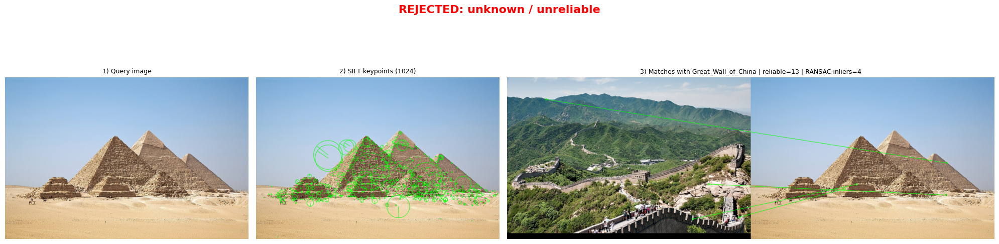

Predicted landmark   : Unknown
Best candidate       : Great_Wall_of_China
Reliable matches     : 13
RANSAC inliers       : 4
Processing time      : 1.588 s
Decision             : REJECTED  -> reliable matches 13 < threshold 15; geometric verification failed: Too few RANSAC inliers (4 < 12)
Localization         : geometric transformation unreliable - no polygon drawn

Candidate ranking:


,Rank,Landmark,Reliable matches,RANSAC inliers,Geometry OK
0,1,Great_Wall_of_China,13,4,False
1,2,Colosseum,12,4,False
2,3,Statue_of_Liberty,12,4,False
3,4,Eiffel_Tower,8,5,False
4,5,Taj_Mahal,7,0,False


In [11]:
# ===== CELL 10: Screenshots of the application output (one landmark, all conditions) =====
first_label = next((lab for lab, cond, r in all_results if lab != "Unknown"), None)
for lab, cond, res in all_results:
    if lab == first_label or lab == "Unknown":
        print(f"\n########  {lab} - {cond}  ########")
        show_result(res)
        if lab == "Unknown":
            break

Saving images (8).jfif to images (8).jfif


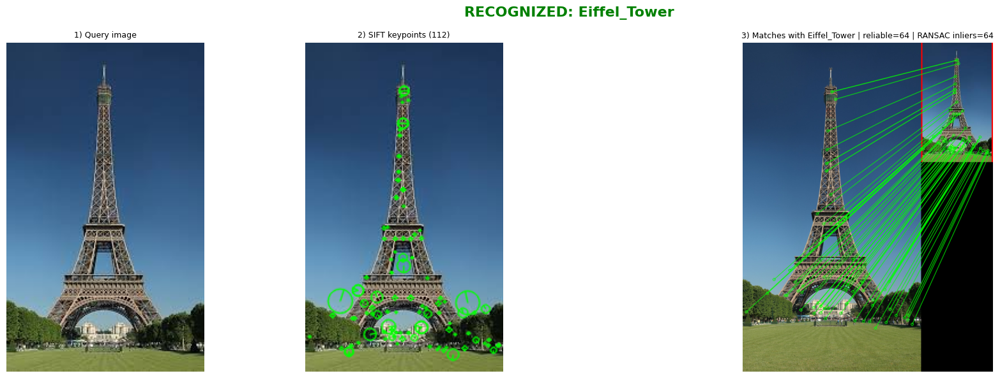

Predicted landmark   : Eiffel_Tower
Best candidate       : Eiffel_Tower
Reliable matches     : 64
RANSAC inliers       : 64
Processing time      : 0.164 s
Decision             : RECOGNIZED  (landmark localized with the red polygon)

Candidate ranking:


,Rank,Landmark,Reliable matches,RANSAC inliers,Geometry OK
0,1,Eiffel_Tower,64,64,True
1,2,Colosseum,3,0,False
2,3,Great_Wall_of_China,1,0,False
3,4,Statue_of_Liberty,1,0,False
4,5,Taj_Mahal,1,0,False


Created landmark_project_submission.zip (database + test images + results)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# ===== CELL 11 (optional): Recognize YOUR OWN image + zip everything for submission =====
try:
    from google.colab import files
    up = files.upload()                                   # choose a landmark photo
    for fname in up:
        img = resize_max(cv2.imread(fname))
        show_result(recognize(img))
except Exception as e:
    print("Upload skipped:", e)

shutil.make_archive("landmark_project_submission", "zip", BASE_DIR)
print("Created landmark_project_submission.zip (database + test images + results)")
try:
    files.download("landmark_project_submission.zip")
except Exception:
    pass